In [99]:
# Celda 1 - Imports y configuración
import numpy as np
import matplotlib.pyplot as plt
import joblib
import polars as pl
from pathlib import Path


RUTA_MODELO_LGBM = "/content/final_lgb_model (1).pkl"      # o .pkl / .txt
RUTA_MODELO_MLP  = "/content/final_mlp_model_2.pth"           #.pkl
RUTA_SCALER_MLP  = "/content/scaler_final_2.pkl"
RUTA_DATASET     = "/content/dataset_final (1) (1).parquet"               # o .csv / .feather



In [100]:
# Celda 2 - Cargar dataset
print("Cargando dataset...")
df_test = pl.read_parquet(RUTA_DATASET)   # cambia a pl.read_csv() si es CSV

# Seleccionar solo el 15% final del dataset
total_rows = df_test.height
cutoff_idx = int(total_rows * 0.85)
df_test = df_test.slice(cutoff_idx)

columna_precio = "v1"
precios_completos = df_test.select(columna_precio).to_numpy().flatten()
print(f"Dataset cargado (15% final): {df_test.shape[0]} filas")

Cargando dataset...
Dataset cargado (15% final): 209067 filas


In [101]:
# Celda 3 - Cargar modelos
print("Cargando modelos...")

# LightGBM
modelo_lgbm = joblib.load(RUTA_MODELO_LGBM)



print("Modelos cargados correctamente")

Cargando modelos...
Modelos cargados correctamente


In [114]:
import torch, joblib

obj = torch.load("/content/final_mlp_model_2.pth", map_location="cpu", weights_only=False)
print(type(obj))

if isinstance(obj, dict):
    # Si trae varias claves, el state_dict suele estar en 'model_state_dict' o 'state_dict'
    print(list(obj.keys())[:10])
    sd = obj.get("model_state_dict", obj.get("state_dict", obj))
    for k, v in sd.items():
        print(k, tuple(v.shape))

scaler = joblib.load("/content/scaler_final_2.pkl")
print("scaler n_features_in_:", scaler.n_features_in_)

<class 'dict'>
['model_state_dict', 'architecture', 'input_dim', 'dropout']
network.0.weight (128, 70)
network.0.bias (128,)
network.1.weight (128,)
network.1.bias (128,)
network.1.running_mean (128,)
network.1.running_var (128,)
network.1.num_batches_tracked ()
network.4.weight (64, 128)
network.4.bias (64,)
network.5.weight (64,)
network.5.bias (64,)
network.5.running_mean (64,)
network.5.running_var (64,)
network.5.num_batches_tracked ()
network.8.weight (3, 64)
network.8.bias (3,)
scaler n_features_in_: 70


In [117]:
import torch, torch.nn as nn

sd = obj.get("model_state_dict", obj.get("state_dict", obj)) if isinstance(obj, dict) else obj

h1, n_in = sd["network.0.weight"].shape
h2       = sd["network.4.weight"].shape[0]
n_out    = sd["network.8.weight"].shape[0]
print("arquitectura:", n_in, "->", h1, "->", h2, "->", n_out)

class MLP(nn.Module):
    def __init__(self, n_in, h1, h2, n_out, p=0.3):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(n_in, h1), nn.BatchNorm1d(h1), nn.ReLU(), nn.Dropout(p),   # 0,1,2,3
            nn.Linear(h1, h2),   nn.BatchNorm1d(h2), nn.ReLU(), nn.Dropout(p),   # 4,5,6,7
            nn.Linear(h2, n_out),                                                # 8
        )
    def forward(self, x):
        return self.network(x)

mlp = MLP(n_in, h1, h2, n_out)
mlp.load_state_dict(sd)
mlp.eval()      # imprescindible: con BatchNorm y Dropout, sin esto las predicciones salen mal

arquitectura: 70 -> 128 -> 64 -> 3


MLP(
  (network): Sequential(
    (0): Linear(in_features=70, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=3, bias=True)
  )
)

In [127]:
X_mlp = scaler.transform(df_test.select(feature_cols).to_numpy())
with torch.no_grad():
    logits = mlp(torch.tensor(X_mlp, dtype=torch.float32))
    preds_prob_mlp = torch.softmax(logits, dim=1).numpy()


In [110]:

feature_cols = [c for c in df_test.columns if c.startswith("v")] + ["OBI_Nivel_1"]
assert len(feature_cols) == modelo_lgbm.num_feature()
assert "label_k_100" not in feature_cols

X_test = df_test.select(feature_cols).to_numpy()
preds_prob_lgbm = modelo_lgbm.predict(X_test)   # (n, 3)

print(f"Features usadas: {len(feature_cols)}")
print(f"Predicciones LGBM: {preds_prob_lgbm.shape}")
print(f"Actividad al 0.55: {((preds_prob_lgbm[:,0]>=0.55)|(preds_prob_lgbm[:,2]>=0.55)).mean()*100:.2f}%")


Features usadas: 70
Predicciones LGBM: (209067, 3)
Actividad al 0.55: 21.54%


Umbral 0.55 | Actividad  LightGBM: 25.76%  MLP: 22.89%  Azar: 25.76%


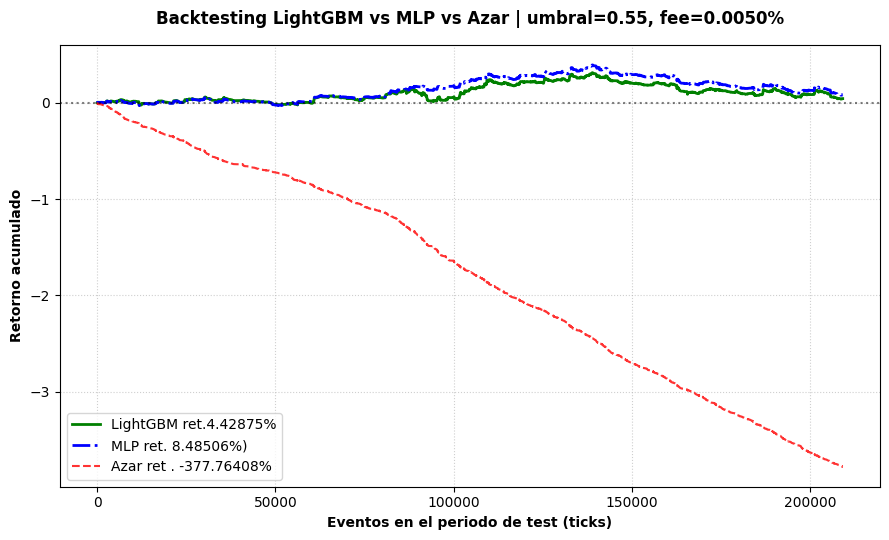

Retorno acumulado final LightGBM: 0.04429
Retorno acumulado final MLP     : 0.08485
Retorno acumulado final Azar    : -3.77764


In [157]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parámetros ---
ts  = 0.55        # umbral de confianza
fee = 0.00005    # comisión por operación (una sola variable para todos)
k   = 100         # horizonte del retorno futuro
assert 0.0 < ts < 1.0

# --- Precios alineados ---
precios = df_test.select("v1").to_numpy().flatten()
assert len(precios) == len(preds_prob_lgbm) == len(preds_prob_mlp), (
    f"Desalineación: precios={len(precios)}, lgbm={len(preds_prob_lgbm)}, mlp={len(preds_prob_mlp)}"
)

# Retorno futuro real a k ticks vista (igual para todos los modelos)
retorno_futuro = np.zeros(len(precios))
retorno_futuro[:-k] = (precios[k:] - precios[:-k]) / precios[:-k]

# --- Funciones ---
def señales(probs, ts):
    y = np.ones(len(probs), dtype=int)       # 1 = neutral
    y[probs[:, 0] >= ts] = 0                 # DOWN -> venta
    y[probs[:, 2] >= ts] = 2                 # UP   -> compra
    return y

def curva(y, retorno, fee):
    ben = np.zeros(len(y))
    ben[y == 2] =  retorno[y == 2] - fee
    ben[y == 0] = -retorno[y == 0] - fee
    return np.cumsum(ben)

# --- Señales de cada modelo ---
y_lgbm = señales(preds_prob_lgbm, ts)
y_mlp  = señales(preds_prob_mlp,  ts)

# --- Azar: mismas señales de LightGBM, pero barajadas entre los ticks operativos ---
rng = np.random.default_rng(42)
y_azar = y_lgbm.copy()
idx_op = np.where(y_azar != 1)[0]
y_azar[idx_op] = rng.permutation(y_azar[idx_op])

# --- Curvas ---
cum_lgbm = curva(y_lgbm, retorno_futuro, fee)
cum_mlp  = curva(y_mlp,  retorno_futuro, fee)
cum_azar = curva(y_azar, retorno_futuro, fee)

# --- Actividad de cada uno ---
act = lambda y: (y != 1).mean() * 100
print(f"Umbral {ts:.2f} | Actividad  LightGBM: {act(y_lgbm):.2f}%  MLP: {act(y_mlp):.2f}%  Azar: {act(y_azar):.2f}%")

# --- Gráfico ---
plt.figure(figsize=(9, 5.5))
plt.plot(cum_lgbm, color="green", linewidth=2,                label=f"LightGBM ret.{100*cum_lgbm[-1]:.5f}%")
plt.plot(cum_mlp,  color="blue",  linewidth=2, linestyle="-.", label=f"MLP ret. {100*cum_mlp[-1]:.5f}%)")
plt.plot(cum_azar, color="red",   linestyle="--", alpha=0.8,   label=f"Azar ret . {100*cum_azar[-1]:.5f}%")

plt.title(f"Backtesting LightGBM vs MLP vs Azar | umbral={ts:.2f}, fee={fee*100:.4f}%",
          fontsize=12, fontweight="bold", pad=15)
plt.xlabel("Eventos en el periodo de test (ticks)", fontweight="bold")
plt.ylabel("Retorno acumulado", fontweight="bold")
plt.axhline(0, color="black", linestyle=":", alpha=0.5)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig("comparativa_backtesting.png", dpi=150)
plt.show()

print(f"Retorno acumulado final LightGBM: {cum_lgbm[-1]:.5f}")
print(f"Retorno acumulado final MLP     : {cum_mlp[-1]:.5f}")
print(f"Retorno acumulado final Azar    : {cum_azar[-1]:.5f}")

Umbral 0.55 | Actividad  LightGBM: 26.09%  MLP: 22.89%  Azar: 26.09%


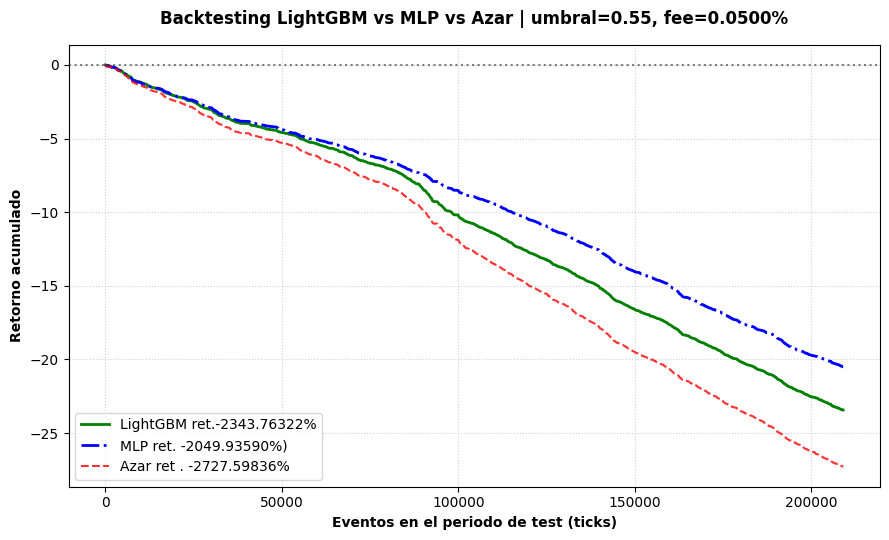

Retorno acumulado final LightGBM: -23.43763
Retorno acumulado final MLP     : -20.49936
Retorno acumulado final Azar    : -27.27598


In [160]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parámetros ---
ts  = 0.55        # umbral de confianza
fee = 0.0005    # comisión por operación (una sola variable para todos)
k   = 100         # horizonte del retorno futuro
assert 0.0 < ts < 1.0

# --- Precios alineados ---
precios = df_test.select("v1").to_numpy().flatten()
assert len(precios) == len(preds_prob_lgbm) == len(preds_prob_mlp), (
    f"Desalineación: precios={len(precios)}, lgbm={len(preds_prob_lgbm)}, mlp={len(preds_prob_mlp)}"
)

# Retorno futuro real a k ticks vista (igual para todos los modelos)
retorno_futuro = np.zeros(len(precios))
retorno_futuro[:-k] = (precios[k:] - precios[:-k]) / precios[:-k]

# --- Funciones ---
def señales(probs, ts):
    y = np.ones(len(probs), dtype=int)       # 1 = neutral
    y[probs[:, 0] >= ts] = 0                 # DOWN -> venta
    y[probs[:, 2] >= ts] = 2                 # UP   -> compra
    return y

def curva(y, retorno, fee):
    ben = np.zeros(len(y))
    ben[y == 2] =  retorno[y == 2] - fee
    ben[y == 0] = -retorno[y == 0] - fee
    return np.cumsum(ben)

# --- Señales de cada modelo ---
y_lgbm = señales(preds_prob_lgbm, ts)
y_mlp  = señales(preds_prob_mlp,  ts)

# --- Azar: mismas señales de LightGBM, pero barajadas entre los ticks operativos ---
rng = np.random.default_rng(42)
y_azar = y_lgbm.copy()
idx_op = np.where(y_azar != 1)[0]
y_azar[idx_op] = rng.permutation(y_azar[idx_op])

# --- Curvas ---
cum_lgbm = curva(y_lgbm, retorno_futuro, fee)
cum_mlp  = curva(y_mlp,  retorno_futuro, fee)
cum_azar = curva(y_azar, retorno_futuro,fee)

# --- Actividad de cada uno ---
act = lambda y: (y != 1).mean() * 100
print(f"Umbral {ts:.2f} | Actividad  LightGBM: {act(y_lgbm):.2f}%  MLP: {act(y_mlp):.2f}%  Azar: {act(y_azar):.2f}%")

# --- Gráfico ---
plt.figure(figsize=(9, 5.5))
plt.plot(cum_lgbm, color="green", linewidth=2,                label=f"LightGBM ret.{100*cum_lgbm[-1]:.5f}%")
plt.plot(cum_mlp,  color="blue",  linewidth=2, linestyle="-.", label=f"MLP ret. {100*cum_mlp[-1]:.5f}%)")
plt.plot(cum_azar, color="red",   linestyle="--", alpha=0.8,   label=f"Azar ret . {100*cum_azar[-1]:.5f}%")

plt.title(f"Backtesting LightGBM vs MLP vs Azar | umbral={ts:.2f}, fee={fee*100:.4f}%",
          fontsize=12, fontweight="bold", pad=15)
plt.xlabel("Eventos en el periodo de test (ticks)", fontweight="bold")
plt.ylabel("Retorno acumulado", fontweight="bold")
plt.axhline(0, color="black", linestyle=":", alpha=0.5)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig("comparativa_backtesting.png", dpi=150)
plt.show()

print(f"Retorno acumulado final LightGBM: {cum_lgbm[-1]:.5f}")
print(f"Retorno acumulado final MLP     : {cum_mlp[-1]:.5f}")
print(f"Retorno acumulado final Azar    : {cum_azar[-1]:.5f}")